# Geodesic Methods for Constraint-Preserving Optimization via Parametrization-Induced Geometry

**Reproducibility notebook** — A. Bhaya, H. Mirandola, C. Mayrink Verdun

**Code repository:** <https://github.com/mirandola/geodesic-gd>

This notebook regenerates every figure and table of the numerical section of the paper and
checks numerically the inequalities behind its main theorems. It is a thin, commented layer over
the package `geogd` (charts, benchmarks, methods) and the scripts in `scripts/`; nothing is
re-implemented here, so the notebook and the paper share one code path.

| Section of this notebook | Item of the paper |
|---|---|
| 1. The geodesic step in closed form | Example 5.1 (orthant), eq. (18) (spherical chart of the simplex) |
| 2. Families A and B | Table 1, Figures 1 and 2 |
| 3. Chart exits | paragraph "Chart exits" of Section 7 |
| 4. Likelihood objectives | Table 2 |
| 5. Checks of the theorems | Theorem 5.4, Propositions 6.2–6.3, Lemma 5.7, Theorem 5.8, Remark 5.9 |

Numbering follows the journal version of the paper. Everything is deterministic (fixed seeds).
Running the whole notebook takes about six minutes on a laptop; the slowest cell is the
five-seed likelihood study of Section 4.

**Requirements:** Python ≥ 3.10, `numpy`, `matplotlib` (see `requirements.txt`). Run it from the
`code/` folder.

In [1]:
import sys, math, platform
from pathlib import Path

sys.dont_write_bytecode = True                      # keep the source tree clean
ROOT = Path.cwd() if (Path.cwd() / "geogd").is_dir() else Path.cwd() / "code"
sys.path[:0] = [str(ROOT), str(ROOT / "scripts")]

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import HTML, display

import generate_boundary_comparative_graphs as GB   # protocol, plotting style, Families A and B
import generate_likelihood_benchmarks as GL          # likelihood family, chart-exit diagnostic
import kl_lyapunov_checks as KL                      # Theorem 5.4 and Proposition 6.3
import local_acceleration_checks as ACC              # Lemma 5.7, Theorem 5.8, Remark 5.9
from geogd.benchmarks import make_all, make_all_euclid, random_spd
from geogd.charts import OrthantChart, SimplexSphereChart

%matplotlib inline
matplotlib.rcParams["figure.dpi"] = 110

N_SEEDS = 5        # seeds used for the robustness columns (as in the paper)
TOL = GB.TOL       # tolerance 1e-6 on the objective gap


def show_table(header, rows, caption=""):
    """Small HTML table helper (avoids a pandas dependency)."""
    th = "".join(f"<th style='text-align:center'>{h}</th>" for h in header)
    tr = "".join("<tr>" + "".join(f"<td style='text-align:center'>{c}</td>" for c in r) + "</tr>" for r in rows)
    display(HTML(f"<table><caption>{caption}</caption><thead><tr>{th}</tr></thead><tbody>{tr}</tbody></table>"))


def sci(v):
    return "&lt;1e-16" if v < 1e-16 else f"{v:.1e}"

## 1. The geodesic step in closed form

The methods of the paper take a Euclidean gradient step on the lifted objective
$L=\ell\circ\phi$ in chart coordinates and map it back through $\phi$. In the two charts for which
the paper proves global results the step is explicit:

* **orthant, square chart** $x=z^{\odot2}/4$ (Example 5.1):
  $\;x_{k+1,i}=x_{k,i}\big(1-\tfrac{\eta}{2}\,\partial_i\ell(x_k)\big)^2$;
* **simplex, spherical chart** $x=u^{\odot2}$, $\|u\|=1$ (eq. (18)):
  $\;x_{k+1,i}=x_{k,i}\big(\cos\theta_k-\sin\theta_k\,\delta_i(x_k)/D(x_k)\big)^2$, $\;\theta_k=2\eta D(x_k)$.

The cell below checks, on a random convex quadratic, that the chart implementation in
`geogd.charts` coincides with these closed forms and that feasibility holds by construction.

In [2]:
rng = np.random.default_rng(0)
n = 6
Q, xbar = random_spd(rng, n), rng.normal(size=n)
grad = lambda x: Q @ (x - xbar)                     # gradient of 1/2 (x - xbar)^T Q (x - xbar)
eta = 0.02

# Orthant: chart step z -> z - eta * grad L(z), then x = phi(z)
x = rng.uniform(0.5, 1.5, size=n)
z = OrthantChart.chi(x)                             # z = 2 sqrt(x)
x_chart = OrthantChart.phi(z - eta * OrthantChart.grad_L(z, grad(x)))
x_closed = x * (1 - 0.5 * eta * grad(x)) ** 2
print("orthant : max |chart step - closed form| =", np.max(np.abs(x_chart - x_closed)),
      "| min coordinate =", x_closed.min())

# Simplex: Riemannian gradient step along a great circle of the sphere u = sqrt(p)
p = x / x.sum()
g = grad(p)
delta = g - p @ g
D = np.sqrt(np.sum(p * delta**2))
theta = 2 * eta * D
p_closed = p * (np.cos(theta) - np.sin(theta) * delta / D) ** 2
p_chart = SimplexSphereChart.geodesic_step(p, g, eta)
print("simplex : max |chart step - closed form| =", np.max(np.abs(p_chart - p_closed)),
      "| sum =", p_closed.sum(), "| min coordinate =", p_closed.min())

orthant : max |chart step - closed form| = 2.220446049250313e-16 | min coordinate = 0.5489779985766351
simplex : max |chart step - closed form| = 0.0 | sum = 1.0 | min coordinate = 0.04102679853843358


## 2. Families A and B (Table 1, Figures 1 and 2)

**Methods.** Projected gradient (PGD, APGD), mirror descent (MD, AMD; entropy on the orthant and
simplex, Burg potential on the positive semidefinite cone), and the geodesic methods GGD and AGGD
in the square chart (orthant), the affine chart (simplex), and the Cholesky chart (PSD cone);
on the simplex also GGD-S, the spherical step.

**Protocol.** Same initialization for all methods, 150 iterations, constant step tuned over a
logarithmic grid: among the stable runs (finite iterates, final gap not above the initial one) the
one with the smallest final gap is kept (`geogd.methods.tune_and_run`).

**Objectives.** *Family A* — convex quadratics in the chart variables, so the lifted objective is
convex and smooth on the chart while $\nabla\ell$ blows up on the boundary (the methods that work in
$x$ receive the gradient at a slightly interior point). *Family B* — convex quadratics in $x$ with
a boundary minimizer prescribed through the optimality conditions; every method receives a regular
gradient, and the orthant instance is a non-negative least-squares problem.

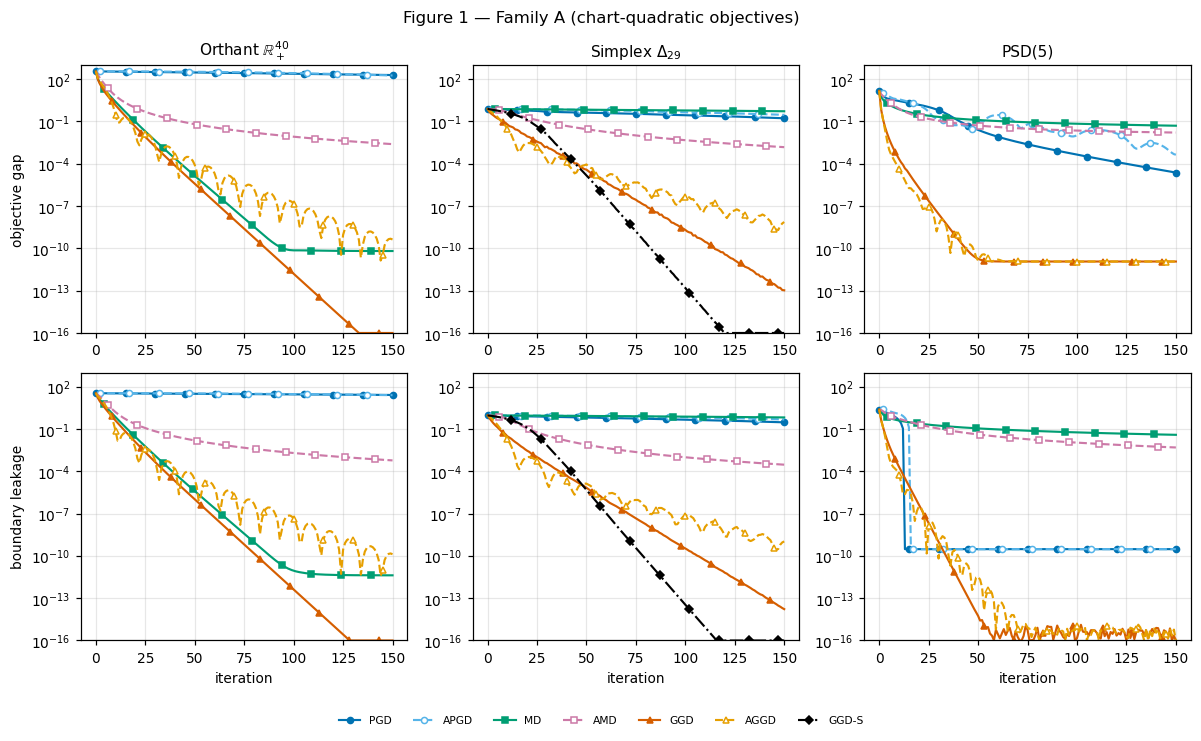

In [3]:
resA = GB.run_family(make_all, GB.SEED)             # Family A, reported seed
resB = GB.run_family(make_all_euclid, GB.SEED)      # Family B, reported seed

figA = GB.plot_family(resA)
figA.suptitle("Figure 1 — Family A (chart-quadratic objectives)", y=1.02);

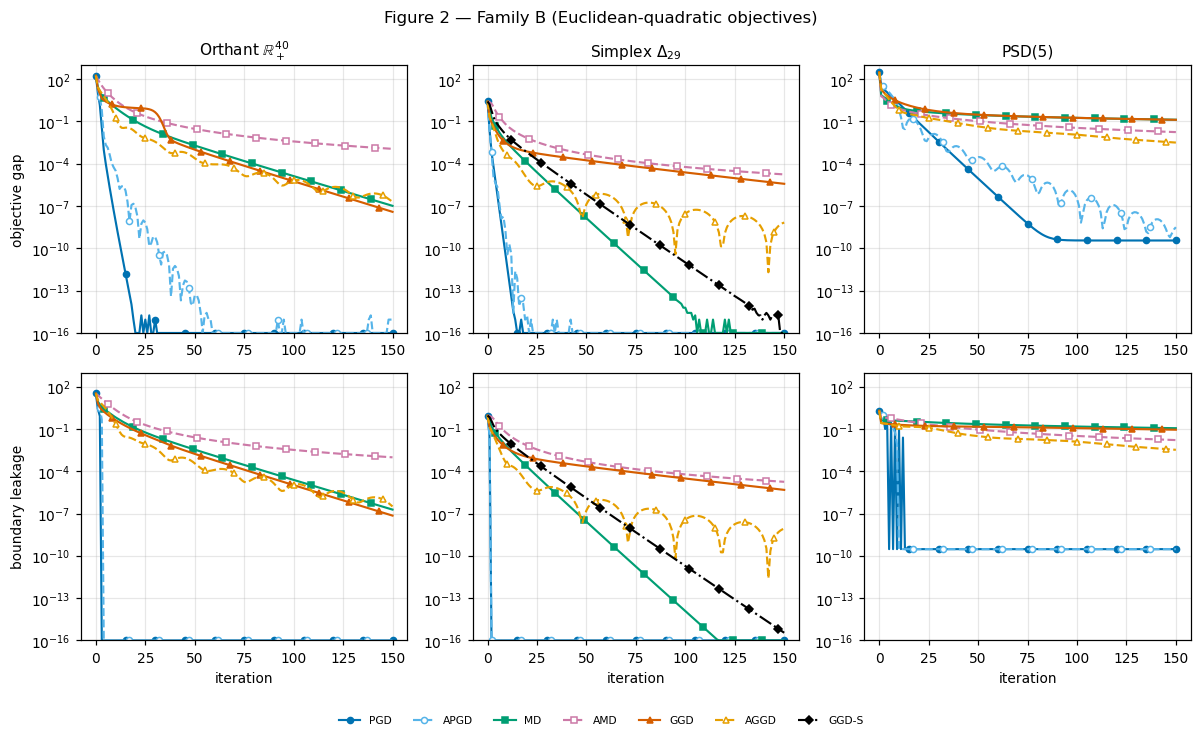

In [4]:
figB = GB.plot_family(resB)
figB.suptitle("Figure 2 — Family B (Euclidean-quadratic objectives)", y=1.02);

**Table 1.** Final objective gap after 150 iterations and, in parentheses, the first iteration at
which the gap falls below $10^{-6}$ ("–": not reached).

In [5]:
def cell(res, bench, m):
    if m not in res[bench]:
        return "n/a"
    r = res[bench][m]
    return f"{sci(max(r['final'], 0.0))} ({'–' if r['hit'] is None else r['hit']})"

benches = ["orthant", "simplex", "psd"]
header = ["method"] + [f"A: {b}" for b in benches] + [f"B: {b}" for b in benches]
rows = [[m] + [cell(resA, b, m) for b in benches] + [cell(resB, b, m) for b in benches] for m in GB.COLS]
show_table(header, rows, "Table 1 (reported seed)")

method,A: orthant,A: simplex,A: psd,B: orthant,B: simplex,B: psd
PGD,1.9e+02 (–),1.7e-01 (–),2.4e-05 (–),<1e-16 (8),<1e-16 (5),3.6e-10 (58)
APGD,1.8e+02 (–),2.9e-01 (–),4.4e-04 (–),8.9e-16 (16),<1e-16 (6),3.2e-09 (80)
MD,6.5e-11 (60),5.3e-01 (–),5.0e-02 (–),1.0e-07 (127),<1e-16 (36),1.3e-01 (–)
AMD,2.5e-03 (–),1.5e-03 (–),1.6e-02 (–),1.1e-03 (–),1.8e-05 (–),1.8e-02 (–)
GGD,<1e-16 (55),1.1e-13 (69),1.2e-11 (22),3.9e-08 (118),3.8e-06 (–),1.3e-01 (–)
AGGD,4.3e-10 (63),7.4e-09 (81),1.2e-11 (18),2.0e-07 (113),6.8e-09 (43),3.2e-03 (–)
GGD-S,n/a,<1e-16 (58),n/a,n/a,<1e-16 (49),n/a


**Robustness over five seeds.** The same protocol is repeated on `N_SEEDS` seeds; the table reports
on how many seeds each method reaches the tolerance and the median first hitting iteration.

In [6]:
def robustness(make):
    runs = [GB.run_family(make, sd) for sd in range(N_SEEDS)]
    out = {}
    for b in benches:
        for m in GB.COLS:
            if m not in runs[0][b]:
                continue
            hits = [r[b][m]["hit"] for r in runs]
            reached = [h for h in hits if h is not None]
            med = np.median([h if h is not None else GB.ITERS + 1 for h in hits])
            out[(b, m)] = f"{len(reached)}/{N_SEEDS}" + (f", k={med:.0f}" if med <= GB.ITERS else "")
    return out

robA, robB = robustness(make_all), robustness(make_all_euclid)
rows = [[m] + [robA.get((b, m), "n/a") for b in benches] + [robB.get((b, m), "n/a") for b in benches] for m in GB.COLS]
show_table(header, rows, "Seeds reaching 1e-6 within 150 iterations, and median first hitting iteration")

method,A: orthant,A: simplex,A: psd,B: orthant,B: simplex,B: psd
PGD,0/5,0/5,0/5,"5/5, k=17","5/5, k=5","5/5, k=26"
APGD,0/5,0/5,0/5,"5/5, k=16","5/5, k=6","5/5, k=34"
MD,"4/5, k=77",0/5,0/5,1/5,"5/5, k=29",0/5
AMD,0/5,0/5,0/5,0/5,0/5,0/5
GGD,"5/5, k=47","5/5, k=73","5/5, k=32",1/5,1/5,0/5
AGGD,"5/5, k=58","5/5, k=86","5/5, k=23",2/5,"5/5, k=41",0/5
GGD-S,n/a,"5/5, k=58",n/a,n/a,"5/5, k=26",n/a


**Reading.** In Family A the chart methods are the only ones that reach the tolerance on all three
benchmarks; in Family B the ranking reverses and the projected methods win, because the projection
identifies the active face in finitely many iterations while the chart methods approach it only
geometrically (Proposition 5.6). Neither family supports a claim that the geodesic methods dominate
projected methods in general.

## 3. Chart exits

GGD and AGGD are run **without reflection**, as unconstrained steps in the chart variables mapped
through $\phi$. With the tuned steps the chart iterates frequently leave the open chart $V$, and it
matters how:

* on the **orthant** and in the **Cholesky chart**, sign changes are symmetries of $\phi$; for GGD
  the iterates $x_k$ coincide with those of the reflected iteration, and `crossings` counts the
  iterations in which the reflection acts;
* in the **affine simplex chart** sign changes are *not* symmetries: `outside > 0` means that the
  run is a feasible continuation, not a sequence of geodesic steps;
* for **GGD-S**, `outside` counts the iterations in which the reflection $u\mapsto|u|$ acts.

`outside` = gradient evaluations outside $V$; `crossings` = evaluations at which the sign pattern
changes (150 iterations, reported seed, tuned steps).

In [7]:
rows = []
for fam, make, res in (("A", make_all, resA), ("B", make_all_euclid, resB)):
    problems = make(GB.SEED)
    for b in benches:
        for m in ("GGD", "AGGD", "GGD-S"):
            if m in res[b]:
                st = GL.chart_exits(problems[b], m, res[b][m]["eta"], GB.ITERS)
                rows.append([fam, b, m, f"{res[b][m]['eta']:.3g}", st["outside"], st["crossings"]])
show_table(["family", "benchmark", "method", "tuned step", "outside", "crossings"], rows, "Chart exits")

family,benchmark,method,tuned step,outside,crossings
A,orthant,GGD,0.1,149,149
A,orthant,AGGD,0.0562,148,148
A,simplex,GGD,0.0316,149,149
A,simplex,AGGD,0.0178,148,148
A,simplex,GGD-S,0.1,143,143
A,psd,GGD,0.562,0,0
A,psd,AGGD,0.562,128,102
B,orthant,GGD,0.178,149,1
B,orthant,AGGD,0.1,149,132
B,simplex,GGD,0.0316,11,9


Family B is the family in which GGD on the orthant (one reflection in 150 iterations) and GGD-S
(none) operate as the intrinsic methods analyzed in the paper, with steps above the proven
thresholds. In Family A the inactive chart coordinates oscillate around zero and the reflection
acts at essentially every iteration.

## 4. Likelihood objectives (Table 2)

Four maximum-likelihood problems that are not built around a chart:

* **Poisson deconvolution** on $\mathbb{R}^{64}_+$, $\ell(x)=\sum_j(\langle a_j,x\rangle-b_j\log\langle a_j,x\rangle)$,
  banded blur, sparse signal — $\nabla\ell$ is unbounded on part of the boundary;
* **Poisson with a dense design** on $\mathbb{R}^{40}_+$ (control) — $\nabla\ell$ is bounded;
* **Gaussian location mixture** (nonparametric maximum likelihood) on the simplex, $n=60$;
* **Gaussian likelihood** $\ell(X)=\operatorname{tr}(SX)-\log\det X$ on $5\times5$ matrices (interior minimizer $S^{-1}$).

The reference optimal values are computed by an active-set Newton method and certified by duality
bounds (`certificate` below). "EM/RL" is the classical multiplicative update (EM on the simplex,
Richardson–Lucy on the orthant). Budget: 500 iterations. This cell takes about three minutes.

In [8]:
BUDGET = 500
runsC = [GL.run_family(sd, BUDGET) for sd in range(N_SEEDS)]
resC, infoC = runsC[GL.SEED]

for name, info in infoC.items():
    print(f"{name:14s}", {k: (f"{v:.1e}" if isinstance(v, float) else v) for k, v in info.items()})

orthant        {'design': 'blur', 'n': 64, 'm': 64, 'support': 12, 'support_true': 5, 'rows_with_zero_count': 31, 'certificate': '3.0e-16', 'strict_compl_margin': '1.4e-04', 'min_support_mass': '5.8e-01', 'max_mass': '1.6e+02'}
simplex        {'n': 60, 'm': 400, 'support': 6, 'certificate': '2.2e-16', 'strict_compl_margin': '7.1e-05', 'min_support_mass': '6.8e-03'}
psd            {'n': 5, 'cond_S': '1.0e+02', 'interior_minimizer': True}
orthant-dense  {'design': 'dense', 'n': 40, 'm': 120, 'support': 14, 'support_true': 6, 'rows_with_zero_count': 0, 'certificate': '1.2e-14', 'strict_compl_margin': '3.3e-04', 'min_support_mass': '3.8e-01', 'max_mass': '1.1e+01'}


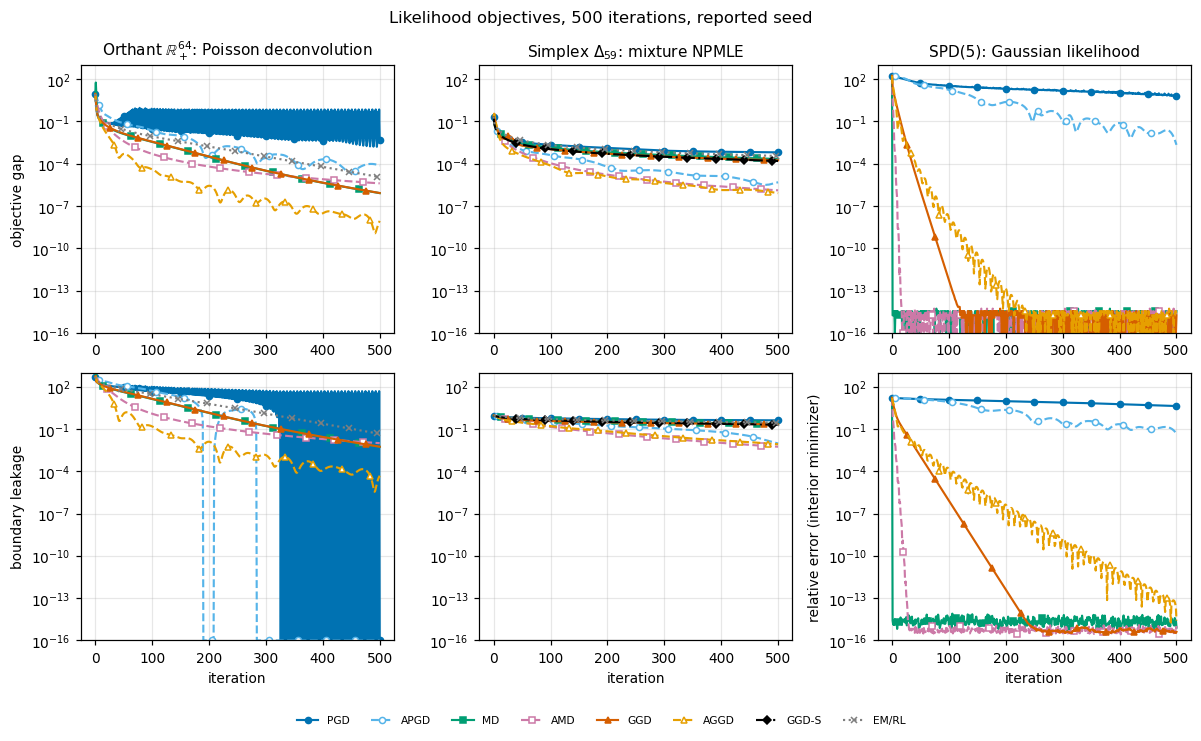

In [9]:
figC = GL.plot_family(resC, GL.MAIN, None, BUDGET)
figC.suptitle("Likelihood objectives, 500 iterations, reported seed", y=1.02);

In [10]:
cols = [("orthant", "Poisson deconv."), ("orthant-dense", "Poisson, dense"), ("simplex", "Mixture"), ("psd", "Gaussian")]
methods = GL.COLS + [GL.MULT]
rows = []
for m in methods:
    row = [m]
    for b, _ in cols:
        if m not in resC[b]:
            row.append("n/a"); continue
        finals = [r[0][b][m]["final"] for r in runsC]
        reached = sum(r[0][b][m]["hit"] is not None for r in runsC)
        row.append(f"{reached}/{N_SEEDS}, {sci(max(float(np.median(finals)), 0.0))}")
    rows.append(row)
show_table(["method"] + [c for _, c in cols], rows,
           "Table 2 — seeds on which the gap falls below 1e-6, and median final gap (500 iterations)")

method,Poisson deconv.,"Poisson, dense",Mixture,Gaussian
PGD,"1/5, 6.2e-04","0/5, 1.2e-05","0/5, 1.0e-03","0/5, 9.0e+00"
APGD,"2/5, 1.2e-06","5/5, 2.1e-08","1/5, 4.9e-06","1/5, 3.3e-01"
MD,"1/5, 4.0e-05","0/5, 3.9e-04","0/5, 3.1e-04","5/5, <1e-16"
AMD,"0/5, 4.1e-06","0/5, 9.6e-06","0/5, 1.6e-06","5/5, <1e-16"
GGD,"1/5, 4.3e-05","0/5, 3.9e-04","0/5, 3.5e-04","5/5, <1e-16"
AGGD,"5/5, 3.7e-08","5/5, 3.6e-07","4/5, 7.0e-07","5/5, 1.8e-15"
GGD-S,n/a,n/a,"0/5, 2.0e-04",n/a
EM/RL,"0/5, 2.6e-04","0/5, 1.3e-03","0/5, 5.8e-04",n/a


**Reading.** The picture is mixed. AGGD is the only method that reaches the tolerance on every seed
in the Poisson deconvolution problem and it does so on four seeds in the mixture problem; on the
dense Poisson control APGD is faster; on the Gaussian likelihood, which is the Burg potential plus a
linear term, mirror descent is exact in one step with unit step size. Plain GGD never wins: on the
orthant it is indistinguishable from entropic mirror descent.

Two qualifications: the projected baselines use a constant step (a line search was not tested),
which penalizes them on the deconvolution problem, where a projection can make the objective
infinite; and the runs in which AGGD does well are outside every theorem of the paper, as the next
cell shows (its extrapolated points lie outside the chart at almost every iteration).

In [11]:
rows = []
for b, label in cols:
    for m in ("GGD", "AGGD", "GGD-S"):
        if m in resC[b]:
            ex = [r[0][b][m]["chart_exits"] for r in runsC]
            rows.append([label, m, " / ".join(str(e["outside"]) for e in ex), " / ".join(str(e["crossings"]) for e in ex)])
show_table(["problem", "method", "outside (per seed)", "crossings (per seed)"], rows,
           f"Chart exits on the likelihood problems ({BUDGET} iterations)")

problem,method,outside (per seed),crossings (per seed)
Poisson deconv.,GGD,11 / 9 / 11 / 11 / 11,4 / 1 / 1 / 2 / 2
Poisson deconv.,AGGD,496 / 496 / 496 / 496 / 495,496 / 496 / 495 / 493 / 492
"Poisson, dense",GGD,0 / 0 / 0 / 0 / 0,0 / 0 / 0 / 0 / 0
"Poisson, dense",AGGD,474 / 472 / 472 / 475 / 470,216 / 193 / 186 / 211 / 139
Mixture,GGD,499 / 499 / 499 / 316 / 499,48 / 27 / 29 / 19 / 25
Mixture,AGGD,499 / 499 / 499 / 499 / 499,301 / 138 / 113 / 88 / 128
Mixture,GGD-S,0 / 0 / 0 / 0 / 0,0 / 0 / 0 / 0 / 0
Gaussian,GGD,499 / 1 / 0 / 0 / 0,1 / 2 / 0 / 0 / 0
Gaussian,AGGD,0 / 0 / 0 / 498 / 0,0 / 0 / 0 / 1 / 0


## 5. Numerical checks of the theorems

The experiments above use tuned steps, larger than the thresholds of the theory. This section
checks the theorems **in their own regime**: step sizes computed from the constants of the
statements, convex quadratic objectives with minimizers on proper faces prescribed through the
optimality conditions.

### 5.1 Global $O(1/k)$ rate with a Kullback–Leibler constant (Theorem 5.4, Proposition 6.3)

*Orthant.* For $\ell$ convex with $\Lambda$-Lipschitz gradient and step
$\eta\le1/\max\{G_0,4\Lambda R_0\}$, Theorem 5.4 states that GGD never leaves the chart and

$$\ell(x_N)-\ell^*\;\le\;\frac{\mathrm{KL}(x^*\Vert x_0)+\tfrac{\eta}{2}\,(\ell(x_0)-\ell^*)}{\eta\,(1-\eta\Lambda\|x^*\|_\infty)\,N}.$$

*Simplex, spherical chart.* For $\eta\le1/(20\beta_S)$, Proposition 6.3 gives
$\ell(x_N)-\ell^*\le\big(\mathrm{KL}(x^*\Vert x_0)+\tfrac52\eta\,(\ell(x_0)-\ell^*)\big)/(2\eta N)$.

The plots show one instance of each; entropic mirror descent with the same step is drawn for
comparison (the two methods discretize the same flow).

orthant : eta = 9.19e-04; smallest factor 1 - eta*g_i/2 = 0.9916 (> 0: no reflection); max gap/bound = 0.149


simplex : eta = 5.64e-04; max gap/bound = 0.131


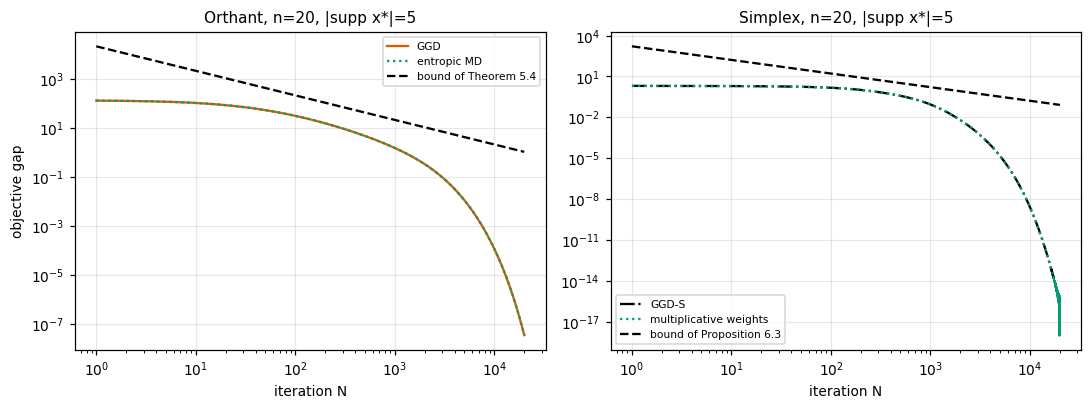

In [12]:
N_IT = 20000
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

# ---- orthant: non-negative least squares with a minimizer on a proper face -------------------
KL.rng = np.random.default_rng(0)
n, support = 20, 5
A, xbar, xs, ell, grad = KL.orthant_instance(n, support)
lam = np.linalg.eigvalsh(A); Lam = lam[-1]
x0 = np.random.default_rng(1).uniform(0.05, 3.0, size=n)
ell0, ell_star = ell(x0), ell(xs)
R0 = np.max(np.abs(xbar)) + math.sqrt(2 * ell0 / lam[0])     # upper bound of sup ||x||_inf on the sublevel set
G0 = math.sqrt(2 * ell0 * Lam)                                # upper bound of sup ||grad ell||_inf
eta = 1.0 / max(G0, 4 * Lam * R0)
c = 1 - eta * Lam * np.max(xs)

x, y = x0.copy(), x0.copy()
gap_ggd, gap_md, min_factor = [], [], np.inf
for k in range(N_IT):
    f = 1 - 0.5 * eta * grad(x)
    min_factor = min(min_factor, f.min())
    x = x * f**2                                 # geodesic step
    y = y * np.exp(-eta * grad(y))               # entropic mirror descent step
    gap_ggd.append(ell(x) - ell_star); gap_md.append(ell(y) - ell_star)
N = np.arange(1, N_IT + 1)
bound = (KL.gen_kl(xs, x0) + 0.5 * eta * (ell0 - ell_star)) / (eta * c * N)
ax = axes[0]
ax.loglog(N, gap_ggd, color="#D55E00", label="GGD")
ax.loglog(N, gap_md, color="#009E73", ls=":", label="entropic MD")
ax.loglog(N, bound, color="k", ls="--", label="bound of Theorem 5.4")
ax.set_title(f"Orthant, n={n}, |supp x*|={support}"); ax.set_xlabel("iteration N"); ax.set_ylabel("objective gap")
ax.legend(); ax.grid(alpha=0.3)
print(f"orthant : eta = {eta:.2e}; smallest factor 1 - eta*g_i/2 = {min_factor:.4f} (> 0: no reflection);"
      f" max gap/bound = {np.max(np.array(gap_ggd) / bound):.3f}")

# ---- simplex, spherical chart ---------------------------------------------------------------
A, xbar, xs, ell, grad = KL.simplex_instance(n, support)
Lam = np.linalg.eigvalsh(A)[-1]
osc = max(np.ptp(grad(e)) for e in np.eye(n))                 # grad ell is affine: the sup is at a vertex
beta_S = 4 * Lam + 2 * osc
eta = 1.0 / (20 * beta_S)
x0 = np.random.default_rng(2).dirichlet(2 * np.ones(n))
ell0, ell_star = ell(x0), ell(xs)
x, y, gap_s, gap_md = x0.copy(), x0.copy(), [], []
for k in range(N_IT):
    x, _, _ = KL.sphere_step(x, grad(x), eta)
    y = y * np.exp(-4 * eta * (grad(y) - grad(y).max())); y /= y.sum()   # multiplicative weights, matched time scale
    gap_s.append(ell(x) - ell_star); gap_md.append(ell(y) - ell_star)
bound = (KL.gen_kl(xs, x0) + 2.5 * eta * (ell0 - ell_star)) / (2 * eta * N)
ax = axes[1]
ax.loglog(N, np.maximum(gap_s, 1e-18), color="k", ls="-.", label="GGD-S")
ax.loglog(N, np.maximum(gap_md, 1e-18), color="#009E73", ls=":", label="multiplicative weights")
ax.loglog(N, bound, color="k", ls="--", label="bound of Proposition 6.3")
ax.set_title(f"Simplex, n={n}, |supp x*|={support}"); ax.set_xlabel("iteration N")
ax.legend(); ax.grid(alpha=0.3)
print(f"simplex : eta = {eta:.2e}; max gap/bound = {np.max(np.array(gap_s) / bound):.3f}")
fig.tight_layout()

The same inequalities are now checked on 200 random instances per chart (random dimension, support,
initial point and step within the admissible range; one instance in four has a degenerate
multiplier). For the orthant: factors of the multiplicative update, the descent inequality, the
one-step Kullback–Leibler inequality and the final rate; for the sphere: the bound
$Q\le4\beta_S\Delta$, the one-step inequality and the rate. "Violation" is the largest value of
left-hand side minus right-hand side (non-positive means the inequality held everywhere).

In [13]:
KL.rng = np.random.default_rng(0)
o = KL.check_orthant()
s = KL.check_sphere()
show_table(["quantity", "value", "expected"], [
    ["orthant: squared factors (1 - eta g_i/2)^2", f"[{o['factor_min']:.3f}, {o['factor_max']:.3f}]", "within [0.25, 2.25]"],
    ["orthant: descent inequality, largest violation", f"{o['descent']:.1e}", "≤ 0"],
    ["orthant: one-step KL inequality, largest violation", f"{o['kl_step']:.1e}", "≤ 0"],
    ["orthant: O(1/N) bound, largest violation", f"{o['rate']:.1e}", "≤ 0"],
    ["orthant: reflections with the step 1/beta_ell", o["reflections_old_step"], "0"],
    ["sphere: Q ≤ 4 beta_S Delta, largest violation", f"{s['Q']:.1e}", "≤ 0"],
    ["sphere: smallest factor cos θ − sin θ δ_i/D", f"{s['factor_min']:.3f}", "> 0"],
    ["sphere: one-step KL inequality, largest violation", f"{s['kl_step']:.1e}", "≤ 0"],
    ["sphere: O(1/N) bound, largest violation", f"{s['rate']:.1e}", "≤ 0"],
], "Theorem 5.4 and Proposition 6.3 on 200 random instances each")

quantity,value,expected
orthant: squared factors (1 - eta g_i/2)^2,"[0.928, 1.030]","within [0.25, 2.25]"
"orthant: descent inequality, largest violation",-3.0e-05,≤ 0
"orthant: one-step KL inequality, largest violation",-5.6e-06,≤ 0
"orthant: O(1/N) bound, largest violation",-7.4e-02,≤ 0
orthant: reflections with the step 1/beta_ell,0,0
"sphere: Q ≤ 4 beta_S Delta, largest violation",-1.1e-01,≤ 0
sphere: smallest factor cos θ − sin θ δ_i/D,0.995,> 0
"sphere: one-step KL inequality, largest violation",-8.4e-05,≤ 0
"sphere: O(1/N) bound, largest violation",-4.8e-01,≤ 0


### 5.2 Local acceleration at non-degenerate minimizers (Lemma 5.7, Theorem 5.8)

Under strict complementarity and strong convexity on the optimal face, the Hessian of the lift at
$z^*=2\sqrt{x^*}$ is block diagonal,

$$\nabla^2L(z^*)=\begin{pmatrix}\operatorname{diag}(\sqrt{x^*_S})\,\nabla^2_{SS}\ell(x^*)\,\operatorname{diag}(\sqrt{x^*_S})&0\\0&\tfrac12\operatorname{diag}(\partial_{\mathcal Z}\ell(x^*))\end{pmatrix}\succeq\mu_L\,\mathrm{Id},$$

so the lift is strongly convex near $z^*$ although $z^*$ lies on the boundary of the chart, and the
accelerated method with constant momentum converges at the rate $1-\kappa^{-1/2}$ when started in
a ball of radius $r/(2\sqrt{1+\kappa})$. The plot shows one instance: plain gradient descent and the
accelerated scheme from the same starting point, with the two predicted rates.

lambda_min of the Hessian of the lift at z* = 0.4276  >=  mu_L of Theorem 5.8(i) = 0.4276
kappa = 79.5; largest distance of z_k, y_k to z* = 2.72e-03  <  r = 6.25e-02 (confinement)


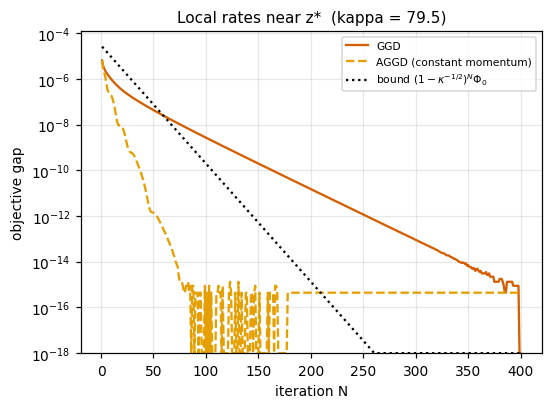

In [14]:
ACC.rng = np.random.default_rng(3); KL.rng = np.random.default_rng(3)
n, support = 12, 4
A, xbar, xs, _, _ = KL.orthant_instance(n, support)
g, L, gL, HL = ACC.lift(A, xbar)
zs = 2 * np.sqrt(xs)
S = xs > 0
mu_L = np.linalg.eigvalsh(HL(zs))[0]
mu_formula = min(np.linalg.eigvalsh(A[np.ix_(S, S)])[0] * xs[S].min(), g(xs)[~S].min() / 2)
print(f"lambda_min of the Hessian of the lift at z* = {mu_L:.4f}  >=  mu_L of Theorem 5.8(i) = {mu_formula:.4f}")

# radius r on which the Hessian stays above mu_L/2 (sampled), and smoothness constant on that ball
sampler = np.random.default_rng(4)
def ball_ok(r):
    for d in sampler.normal(size=(300, n)):
        d *= r * sampler.random() ** (1 / n) / np.linalg.norm(d)
        if np.linalg.eigvalsh(HL(zs + d))[0] < 0.5 * mu_L:
            return False
    return True
r = 1.0
while not ball_ok(r):
    r *= 0.5
r *= 0.5                                             # safety margin: the test above is by sampling
beta = 1.05 * max(np.linalg.eigvalsh(HL(zs + r * d / np.linalg.norm(d)))[-1] for d in sampler.normal(size=(300, n)))
mu = 0.5 * mu_L
kappa = beta / mu
q = (math.sqrt(kappa) - 1) / (math.sqrt(kappa) + 1)

d = sampler.normal(size=n)
z0 = zs + 0.99 * r / (2 * math.sqrt(1 + kappa)) * d / np.linalg.norm(d)
K_IT = 400
z_gd, z, y, Ls = z0.copy(), z0.copy(), z0.copy(), L(zs)
gap_gd, gap_acc, max_dist = [], [], 0.0
for k in range(K_IT):
    z_gd = z_gd - gL(z_gd) / beta                    # Theorem 5.8(ii): GGD
    z_new = y - gL(y) / beta                         # Theorem 5.8(iii): AGGD, constant momentum
    y = z_new + q * (z_new - z); z = z_new
    max_dist = max(max_dist, np.linalg.norm(z - zs), np.linalg.norm(y - zs))
    gap_gd.append(L(z_gd) - Ls); gap_acc.append(L(z) - Ls)
k = np.arange(1, K_IT + 1)
Phi0 = L(z0) - Ls + 0.5 * mu * np.sum((z0 - zs) ** 2)
plt.figure(figsize=(5.4, 3.8))
plt.semilogy(k, np.maximum(gap_gd, 1e-18), color="#D55E00", label="GGD")
plt.semilogy(k, np.maximum(gap_acc, 1e-18), color="#E69F00", ls="--", label="AGGD (constant momentum)")
plt.semilogy(k, np.maximum(Phi0 * (1 - 1 / math.sqrt(kappa)) ** k, 1e-18), color="k", ls=":", label=r"bound $(1-\kappa^{-1/2})^N\Phi_0$")
plt.xlabel("iteration N"); plt.ylabel("objective gap"); plt.ylim(1e-18, None)
plt.title(f"Local rates near z*  (kappa = {kappa:.1f})"); plt.legend(); plt.grid(alpha=0.3)
print(f"kappa = {kappa:.1f}; largest distance of z_k, y_k to z* = {max_dist:.2e}  <  r = {r:.2e} (confinement)")

In [15]:
ACC.rng = np.random.default_rng(5); KL.rng = np.random.default_rng(0)
err, slack = ACC.check_hessian()
viol, exits, rate = ACC.check_potential()
show_table(["quantity", "value", "expected"], [
    ["block formula for the Hessian of the lift at z*, largest error", f"{err:.1e}", "rounding"],
    ["lambda_min − mu_L, smallest value", f"{slack:.1e}", "≥ 0 up to rounding"],
    ["one-step potential inequality (Lemma 5.7), largest violation / Phi_0", f"{viol:.1e}", "≤ 0 up to rounding"],
    ["accelerated linear rate (Theorem 5.8(iii)), largest violation / Phi_0", f"{rate:.1e}", "≤ 0 up to rounding"],
    ["iterates outside the ball B(z*, r)", exits, "0"],
], "Lemma 5.7 and Theorem 5.8 on 300 random instances")

quantity,value,expected
"block formula for the Hessian of the lift at z*, largest error",4.6e-15,rounding
"lambda_min − mu_L, smallest value",-3.3e-15,≥ 0 up to rounding
"one-step potential inequality (Lemma 5.7), largest violation / Phi_0",5.1e-09,≤ 0 up to rounding
"accelerated linear rate (Theorem 5.8(iii)), largest violation / Phi_0",3.8e-10,≤ 0 up to rounding
"iterates outside the ball B(z*, r)",0,0


### 5.3 Global behaviour of AGGD (Remark 5.9) — evidence, not a theorem

Whether AGGD satisfies a global $O(1/k^2)$ bound under convexity of $\ell$ alone is open: the lift
is not convex away from $z^*$ and the accelerated iterates change sign. The cell below runs AGGD
(momentum sequence of Beck–Teboulle, no restart, step $1/\beta$) for 3000 iterations on 300 random
convex quadratics with minimizers on proper faces, one in three degenerate, and reports the largest
value of $(\ell(x_N)-\ell^*)\,(N+1)^2/(4\beta D_\chi(x^*,x_0))$, which the convex theory would bound
by 1.

In [16]:
ACC.rng = np.random.default_rng(5); KL.rng = np.random.default_rng(0)
gl = ACC.check_global()
show_table(["quantity", "value"], [
    ["largest ratio gap · (N+1)² / (4 β D_χ) over all runs and iterations", f"{gl['max_ratio']:.3f}"],
    ["median over runs of the largest ratio", f"{gl['median_ratio']:.3f}"],
    ["runs in which the accelerated iterates change sign", f"{gl['sign_changes']} of {gl['n']}"],
    ["runs in which AGGD ends above GGD", f"{gl['worse_than_ggd']} of {gl['n']}"],
], "AGGD on the global lift: the bound of the convex theory was never violated")

quantity,value
largest ratio gap · (N+1)² / (4 β D_χ) over all runs and iterations,0.372
median over runs of the largest ratio,0.113
runs in which the accelerated iterates change sign,298 of 300
runs in which AGGD ends above GGD,0 of 300


## 6. Environment

In [17]:
print("python    ", platform.python_version())
print("numpy     ", np.__version__)
print("matplotlib", matplotlib.__version__)
print("platform  ", platform.platform())

python     3.13.5
numpy      2.2.4
matplotlib 3.10.1+dfsg1
platform   Linux-6.12.113+deb13-amd64-x86_64-with-glibc2.41
